<a href="https://colab.research.google.com/github/stalingdiaz1-coder/EstadisticaI/blob/main/CUADERNO_ESTADISTICA_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ESTUDIANTES:**

*   Estefani Garcia Prada 2242106
*   Sergio Staling Diaz Gomez 2242799
*   Leyder Santiago Castro Muñoz 2240138





# Primera Parte

Comportamiento de la variable EDAD_PADRE

ESTADÍSTICA DESCRIPTIVA PARA VARIABLES CUANTITATIVAS.

*   Graficos para datos univariados cuantitativos
*   Determinar las medidas descriptivas para datos univariados cuantitativos


In [ ]:
from google.colab import files # Para cargar archivos en google colab
uploaded = files.upload()

Saving BD-EEVV-Nacimientos-2024 (2) (1).zip to BD-EEVV-Nacimientos-2024 (2) (1).zip


In [ ]:
import pandas as pd
import io
io_csv = io.BytesIO(uploaded['BD-EEVV-Nacimientos-2024 (2) (1).zip'])
tabla = pd.read_csv(io_csv, sep = ",", index_col=0, encoding='latin-1', compression='zip')
tabla.head(3)

,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,ATEN_PAR,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
COD_DPTO,,,,,,,,,,,,,,,,,,,,,
76,1,1,1,NaN,2,6,5,2024,5,1,...,2,21/09/2017,2,2,2.0,39,4,11,1.0,1
19,473,3,2,NaN,1,7,4,2024,6,5,...,3,27/06/2023,3,2,2.0,27,3,9,1.0,1
41,298,1,1,NaN,1,6,5,2024,4,1,...,3,23/06/2020,3,2,2.0,28,4,11,1.0,1


In [ ]:
df = tabla[["EDAD_PADRE", "EDAD_MADRE", "N_HIJOSV"]]
df.head(3)

,EDAD_PADRE,EDAD_MADRE,N_HIJOSV
COD_DPTO,,,
76,39,6,2
19,27,4,3
41,28,4,3


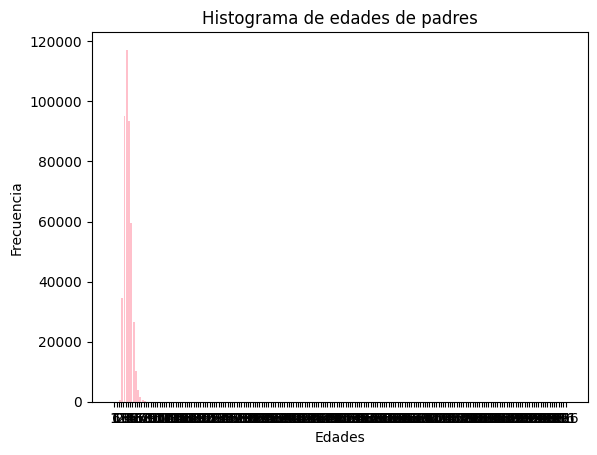

In [ ]:
import matplotlib.pyplot as plot
intervalos = range(min(df.EDAD_MADRE), max(df.EDAD_PADRE)+2,5)
plot.hist(df.EDAD_PADRE, bins = intervalos, color = "pink", rwidth=0.85)
plot.title("Histograma de edades de padres")
plot.xlabel("Edades")
plot.ylabel("Frecuencia")
plot.xticks(intervalos)
plot.show()


El histograma evidencia que la mayoría de los padres en Colombia se concentran entre los 25 y 35 años, lo que refleja que la paternidad es más común en adultos jóvenes. La distribución muestra una ligera asimetría positiva (sesgo hacia la derecha) lo que quiere decir que hay menos casos de padres mayores de 45 años. La forma del gráfico sugiere que la edad de los padres no sigue una distribución tipo normal.

In [ ]:
df1 = df[(df.EDAD_PADRE <120) & (df.EDAD_MADRE !=99) & (df.N_HIJOSV !=99)]
df1.head(5)

,EDAD_PADRE,EDAD_MADRE,N_HIJOSV
COD_DPTO,,,
76,39,6,2
19,27,4,3
41,28,4,3
50,27,2,1
50,31,4,5


/tmp/ipykernel_828/4257905100.py:15: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k" (-> color=(0.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(x,p, "k", linewidth=2, label="Distribución normal", color = "skyblue")


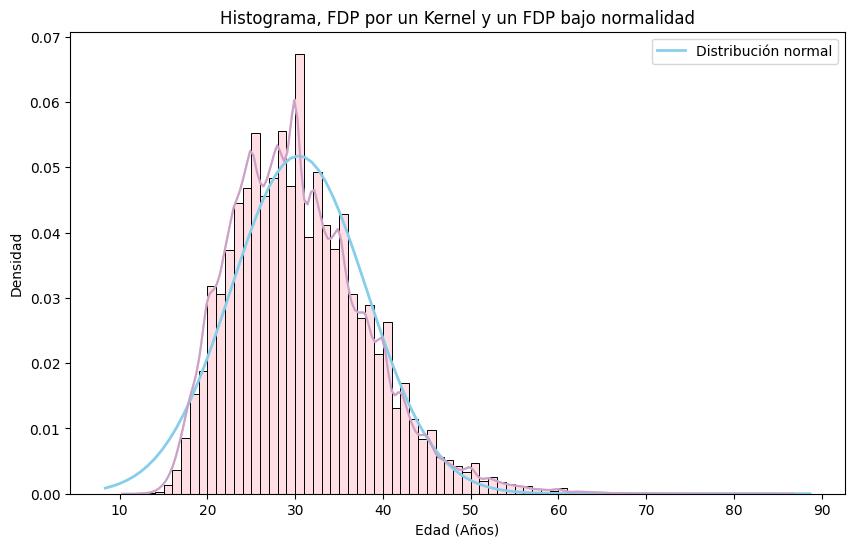

In [ ]:
import seaborn as sns
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt


intervalos1 = range(min(df1.EDAD_PADRE), max(df1.EDAD_PADRE) +1)
plot.figure(figsize=(10,6))
sns.histplot(x = df1.EDAD_PADRE, bins = intervalos1, kde=True, stat="density", color = "pink", edgecolor="black")

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf (x, np.mean(df1.EDAD_PADRE), np.std(df1.EDAD_PADRE))

plt.plot(x,p, "k", linewidth=2, label="Distribución normal", color = "skyblue")

sns.kdeplot(df1.EDAD_PADRE, color= "#c8a2c8")
plt.title("Histograma, FDP por un Kernel y un FDP bajo normalidad")
plt.xlabel("Edad (Años)")
plt.ylabel("Densidad")
plt.legend()

plt.show()

Sea $X:=$ Edad del padre de un recén nacido em Colombia.

DESCRIPTIVAMENTE: Como la función de densidad de probabilidad de los datos estimada por un método Kernel (Linea rosada) no coincide con la función de densidad de probabilidad asumiendo el supuesto de normalidad (Línea azul), $X\sim \text{Normal1} (\text{Media} = (\bar{x},S_x), \text{Varianza}= s^2_x$)$, entonces no asumimos normalidad, de acuerdo con las gráficas.

In [ ]:
#Prueba de hipótesis.
from scipy.stats import shapiro
shapiro(df1.EDAD_PADRE)

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 443803.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9677165978499048), pvalue=np.float64(7.672928032033413e-109))



*   Si el **Valor p** en una prueba de hipótesis es menor que 0.05 se rechaza la hipótesis nula con una confianza del 95%.
*   Si el **Valor p** es una prueba de hipótesis es mayor que 0.05 no se rechaza la hipótesis nula con una confianza del 95%.

En nuestro caso particular, tenemos que pvalue = $7.672928032033413e-109 <0.05$, es decir, se rechaza que la variable aleatoria $X$ la cual es la edad de un padre de un recién nacido en Colombia presenta distribución normal.  
(revisar)


In [ ]:
df1.EDAD_PADRE.count()
len(df1.EDAD_PADRE)

443803

In [ ]:
idx = np.random.randint(len(df1.EDAD_PADRE), size=100)
shapiro(df1.EDAD_PADRE.index[idx])

ShapiroResult(statistic=np.float64(0.8555630030166189), pvalue=np.float64(1.914128185190227e-08))

En nuestro caso particular, tenemos que pvalue = $4.3343627117957905e-08 <0.05$, es decir, se rechaza que la variable aleatoria $X$ la cual es la edad de un padre de un recién nacido en Colombia presenta distribución normal. (revisar)  

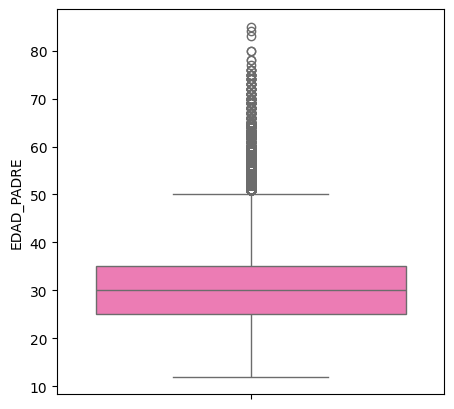

In [ ]:
import seaborn
plt.figure(figsize=(5,5))
sns.boxplot(df1.EDAD_PADRE, color = "#ff69b4" , saturation=0.75)
plot.show()

El diagrama de cajas y bigotes de la variable EDAD_PADRE muestra que las edades se concentran principalmente entre los 25 y los 35 años, con una mediana aproximada de 30 años. El 50 % central de los datos se encuentra dentro de este intervalo, lo que evidencia una concentración importante de las edades alrededor de la mediana. Los bigotes se extienden aproximadamente desde los 12 hasta los 50 años, mientras que se observa una cantidad considerable de valores atípicos por encima de este último valor, que alcanzan edades cercanas a los 85 años. Asimismo, la distribución presenta una asimetría positiva, debido a la extensión de los datos hacia las edades más altas. En conclusión, aunque la mayor concentración de padres se encuentra en edades relativamente jóvenes, también existen numerosos registros de padres de mayor edad que amplían la distribución hacia la derecha.

In [ ]:
import plotly.express as px

plt.figure(figsize=(5,5))
fig = px.strip (df1.EDAD_PADRE, orientation= "h")
fig.show()

<Figure size 500x500 with 0 Axes>

El diagrama de puntos, muestra la distribución de edad de los padres en Colombia, determinada que la mayoría son adultos jóvenes o de mediana edad (entre 20 y 50 años, donde la densidad es más alta), con una presencia menor de padres mayores.

In [ ]:
import numpy as np
from scipy.stats import skew, kurtosis
def calcular_estadisticas(datos):
  media = np.mean(datos)
  varianza = np.var(datos)
  asimetria = skew(datos)
  curtosis = kurtosis(datos)
  return media, varianza, asimetria, curtosis

media, varianza, asimetria, curtosis = calcular_estadisticas(df1.EDAD_PADRE)

print(f"Media: {np.mean(df1.EDAD_PADRE)}")
print(f"Varianza: {np.var(df1.EDAD_PADRE)} y la desviación estándar es de {np.std(df1.EDAD_PADRE)}")
print(f"Asimetría: {skew(df1.EDAD_PADRE)}")
print(f"Curtosis: {kurtosis(df1.EDAD_PADRE)}")

Media: 30.3998102761811
Varianza: 59.42390174029583 y la desviación estándar es de 7.70869001454176
Asimetría: 0.7421856233957171
Curtosis: 0.8605013938482262


Un adulto joven, rondando los 30 años.

La mayoría se encuentra en una franja bastante homogénea de entre 23 y 38 años (baja dispersión).

Existe una minoría significativa (pero pequeña) de padres de edad avanzada (hasta 80+ años) que generan la asimetría hacia la derecha.

La distribución es puntiaguda (leptocúrtica), concentrando muchos casos exactos en edades específicas (probablemente edades enteras muy comunes como 25, 28, 30, 32).



# SEGUNDA PARTE

**Diagrama de dispersión y la recta de regresión para datos bivariados.**

Vamos a determnar si una variable está correlacionada o depende de otra variable.

**En este caso las variables Edad de padres y Numeros de hijos**

*   Una variable depende de la otra, cuando la ejecución de esta se ve afectada por la variable *independiente*.
*Ejemplo:* El precio de una vivienda depende del número de habitaciones, ya que entre más habitaciones se tiene mayor precio.
*   Una variable está correlacionada con otra, cuando guardan cierta relación, pero no es posible hablar de dependencia. *Ejemplo:* Consumo de arroz y de carne, ya que se ha visto que al comerse más arroz se come más carnde, pero no hay una dependencia de estas dos variables.  



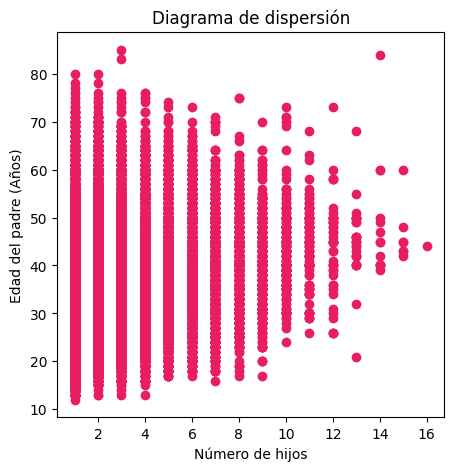

In [ ]:
import plotly.express as px
import matplotlib.pyplot as plt
plt.figure(figsize=(5,5))
plt.scatter (df1['N_HIJOSV'], df1['EDAD_PADRE'], color = "#E91D62", marker = "o")
plt.title("Diagrama de dispersión")
plt.xlabel("Número de hijos")
plt.ylabel("Edad del padre (Años)")
plt.show()

Este gráfico nos muestra que en esta muestra específica, la edad del padre no es un factor determinante para decidir tener más o menos hijos. Hay padres jóvenes con muchos hijos, padres mayores con pocos hijos, y viceversa.

La mayoría de la población estudiada se concentra en familias de 1 a 5 hijos, con edades muy variadas. Los casos de familias muy numerosas (más de 10 hijos) son raros (pocos puntos) y no siguen un patrón de edad específico.

In [ ]:
from sklearn.linear_model import LinearRegression
modelo = LinearRegression()
modelo.fit(np.array(df1["N_HIJOSV"]).reshape(-1,1), np.array(df1["EDAD_PADRE"]).reshape(-1,1))
predicciones = modelo.predict(np.array(df1["N_HIJOSV"]).reshape(-1,1))
predicciones

array([[30.73973187],
       [32.9549449 ],
       [32.9549449 ],
       ...,
       [28.52451884],
       [28.52451884],
       [30.73973187]])

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Creating legend with loc="best" can be slow with large amounts of data.



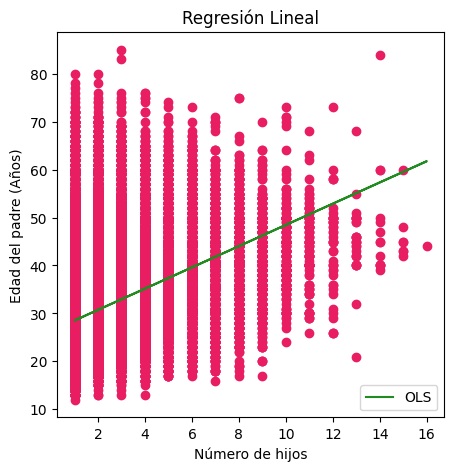

In [ ]:
import plotly.express as px
import matplotlib.pyplot as plt
plt.figure(figsize=(5,5))
plt.scatter (df1['N_HIJOSV'], df1['EDAD_PADRE'], color = "#E91D62", marker = "o")
plt.plot(df1["N_HIJOSV"], predicciones, color = "#228B22", linestyle = "-", label="OLS")
plt.title("Regresión Lineal")
plt.xlabel("Número de hijos")
plt.ylabel("Edad del padre (Años)")
plt.legend()
plt.show()

Matemáticamente: Existe una relación lineal positiva (a más hijos, mayor edad),
pero es una relación débil.

Estadísticamente: La regresión lineal no es el mejor modelo para explicar estos datos. La gran dispersión vertical (las columnas largas de puntos) indica que dentro de cada número de hijos, las edades varían muchísimo.

Práctica: El gráfico sugiere que las familias numerosas (más de 10 hijos) en esta muestra tienden a tener padres de mayor edad (quizás porque les tomó más tiempo tener tantos hijos), pero para familias pequeñas (1 a 5 hijos), la edad del padre es muy variada y no depende estrictamente del número de hijos.

In [ ]:
import numpy as np
from scipy.stats import spearmanr
from scipy.stats import kendalltau

pearson_corr = np.corrcoef(df1["N_HIJOSV"], df1["EDAD_PADRE"])[0,1]
spearman_corr, _ = spearmanr(df1["N_HIJOSV"], df1["EDAD_PADRE"])
kendall_corr, _ = kendalltau(df1["N_HIJOSV"], df1["EDAD_PADRE"])

print("Los coeficientes de correlación son los siguientes: ")
print(f"Correlación de Pearson: {pearson_corr}")
print(f"Correlación de Spearman: {spearman_corr}")
print(f"Correlación de Kendall: {kendall_corr}")


Los coeficientes de correlación son los siguientes: 
Correlación de Pearson: 0.325494435732471
Correlación de Spearman: 0.3532851710238932
Correlación de Kendall: 0.27961408497742013


Para la interpretación de los coeficientes de correlación nos ayudaremos de la referencia:
Landis, J. R., & Koch, G. G. (1977). The measurement of observer agreement for categorical data. biometrics, 159-174. [The Measurement of Observer Agreement for Categorical Data](https://2024.sci-hub.st/2153/7a79ed8d1ae20779cbcdf5ab36348bc2/landis1977.pdf)


*  X y Y son independientes o no están correlacionadas (No hay): $\rho (X,Y) = 0, \eta (X,Y) = 0, \kappa (X,Y) = 0$
*   Y depende insignificadamente de X o X y Y están insignificadamente (Insignificante): correlacionadas si $0 < \vert \rho (X,Y) \vert < 0.2$, $0 < \vert \eta (X,Y) \vert < 0.2$, $0 < \vert \kappa (X,Y) \vert < 0.2$
*    Y depende discretamente de X o X y Y están discretamente correlacionadas (Discreta): si $0.2 < \vert \rho (X,Y) \vert < 0.4$, $0.2 < \vert \eta (X,Y) \vert < 0.4$, $0.2 < \vert \kappa (X,Y) \vert < 0.4$
*    Y depende moderadamente de X o X y Y están moderadamente correlacionadas (Moderada): si $0.4 < \vert \rho (X,Y) \vert < 0.6$, $0.4 < \vert \eta (X,Y) \vert < 0.6$, $0.4 < \vert \kappa (X,Y) \vert < 0.6$
*    Y depende sustancialmente de X o X y Y están sustancialmente correlacionadas  (Sustancial):si $0.6 < \vert \rho (X,Y) \vert < 0.8$, $0.6 < \vert \eta (X,Y) \vert < 0.8$, $0.6 < \vert \kappa (X,Y) \vert < 0.8$
*    Y depende fuertemente de X o X y Y están fuertemente correlacionadas (Fuerte): si $0.8 < \vert \rho (X,Y) \vert < 1$, $0.8 < \vert \eta (X,Y) \vert < 1$, $0.8 < \vert \kappa (X,Y) \vert < 1$



De acuerdo con los coeficientes de correlación, de Pearson, Kendall y Spearman se determina que el número de hijos de un padre y la edad de un recién nacido en Colombia son discretamente correlacionadas.

In [ ]:
df1.EDAD_MADRE = df1.EDAD_MADRE.astype(int)
df1.N_HIJOSV = df1.N_HIJOSV.astype(int)

/tmp/ipykernel_828/1379924369.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_828/1379924369.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

